In [121]:
import numpy as np
import math
import matplotlib.pyplot as plt
%matplotlib inline

In [131]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __radd__(self, other):
        return self + other
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * self.data**(other - 1) * out.grad

        out._backward = _backward
        return out
    
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other**-1

    def exp(self):
        out = Value(math.exp(self.data), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        t = (math.exp(2 * self.data) - 1) / (math.exp(2 * self.data) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad
            
        out._backward = _backward
        return out 

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for v in reversed(topo):
            v._backward()

In [123]:
from graphviz import Digraph

def trace(root):
    """Build a set of all nodes and edges in the computational graph using DFS."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    """Draw a computational graph with graphviz."""
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # Add the node attributes
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

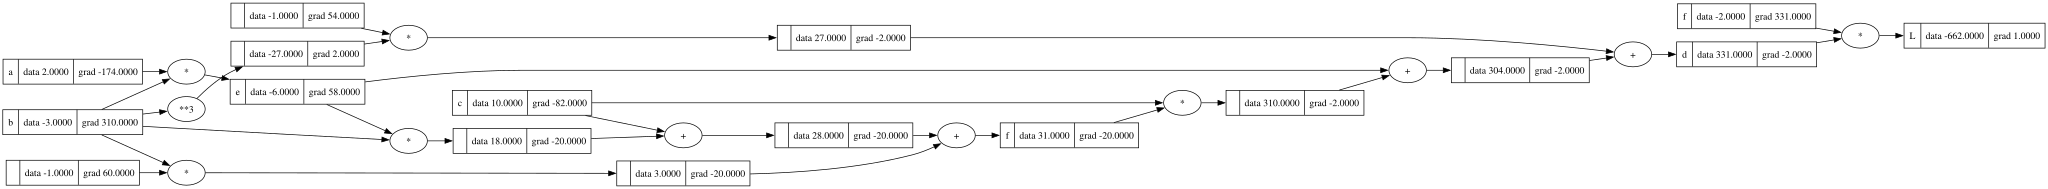

In [124]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
f = e*b + c - b; f.label = 'f'
d = e + c*f - b**3; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'

L.backward()
draw_dot(L)

In [125]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(np.random.randn()) for _ in range(nin)]
        self.b = Value(np.random.randn())

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):  # number of inputs, number of outputs
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out

    def parameters(self):
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params

    # you can also do return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):  # nin: number of inputs, nouts: list of number of outputs per layer
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    

In [126]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])  # 3 inputs, 2 hidden layers with 4 neurons each, 1 output
n(x)  # call the neuron with input x

xs = [[2.0, 3.0, -1.0],
      [3.0, -1.0, 0.5],
      [0.5, 1.0, 1.0],
      [1.0, 1.0, -1.0]]
ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data=0.5025106791819137),
 Value(data=-0.6513077925397557),
 Value(data=0.5435939274489748),
 Value(data=0.8846220442727654)]

In [136]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss.backward()

for p in n.parameters():
    p.grad = 0.0
    p.data = p.data - 0.01 * p.grad  # simple SGD update

print(loss)


Value(data=2.7650761653966858)


In [141]:
for k in range(10000):
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    loss.backward()
    for p in n.parameters():
        p.data -= 0.05 * p.grad
        p.grad = 0.0
    print(k, loss.data)

0 0.000379556675876448
1 0.0003792218048158056
2 0.00037888752521009564
3 0.0003785538354956502
4 0.0003782207341142988
5 0.0003778882195133702
6 0.0003775562901456187
7 0.00037722494446922777
8 0.0003768941809477964
9 0.00037656399805031254
10 0.0003762343942510982
11 0.00037590536802982347
12 0.0003755769178714745
13 0.00037524904226630745
14 0.00037492173970985994
15 0.00037459500870290333
16 0.00037426884775142947
17 0.0003739432553666212
18 0.0003736182300648512
19 0.0003732937703676184
20 0.0003729698748015753
21 0.00037264654189846384
22 0.00037232377019512185
23 0.0003720015582334386
24 0.0003716799045603539
25 0.00037135880772782686
26 0.0003710382662928054
27 0.0003707182788172221
28 0.0003703988438679605
29 0.00037007996001682953
30 0.00036976162584056766
31 0.0003694438399207948
32 0.0003691266008439897
33 0.0003688099072014962
34 0.0003684937575894908
35 0.0003681781506089312
36 0.00036786308486559584
37 0.0003675485589700046
38 0.0003672345715374337
39 0.00036692112118788

In [142]:
ypred

[Value(data=0.995446768938307),
 Value(data=-0.9992308436685242),
 Value(data=-0.9973237576425455),
 Value(data=0.9967237738718755)]